Saving Burgmaier_Genotype_Phenotype_Replication - Null_Null.csv to Burgmaier_Genotype_Phenotype_Replication - Null_Null.csv
Saving Burgmaier_Genotype_Phenotype_Replication - AA709-1837.csv to Burgmaier_Genotype_Phenotype_Replication - AA709-1837.csv
Saving Burgmaier_Genotype_Phenotype_Replication - AA1-708.csv to Burgmaier_Genotype_Phenotype_Replication - AA1-708 (1).csv
Saving Burgmaier_Genotype_Phenotype_Replication - AA2625-4074.csv to Burgmaier_Genotype_Phenotype_Replication - AA2625-4074 (1).csv
Saving Burgmaier_Genotype_Phenotype_Replication - AA1838-2624.csv to Burgmaier_Genotype_Phenotype_Replication - AA1838-2624 (1).csv
Missense variant counts per region:
  AA1_708: 19 unique missense variants
  AA709_1837: 26 unique missense variants
  AA1838_2624: 12 unique missense variants
  AA2625_4074: 19 unique missense variants

Combined dataset: 151 patients
region
AA1838_2624    22
AA1_708        44
AA2625_4074    21
AA709_1837     51
Null_Null      13

── Event rates by region ──
 

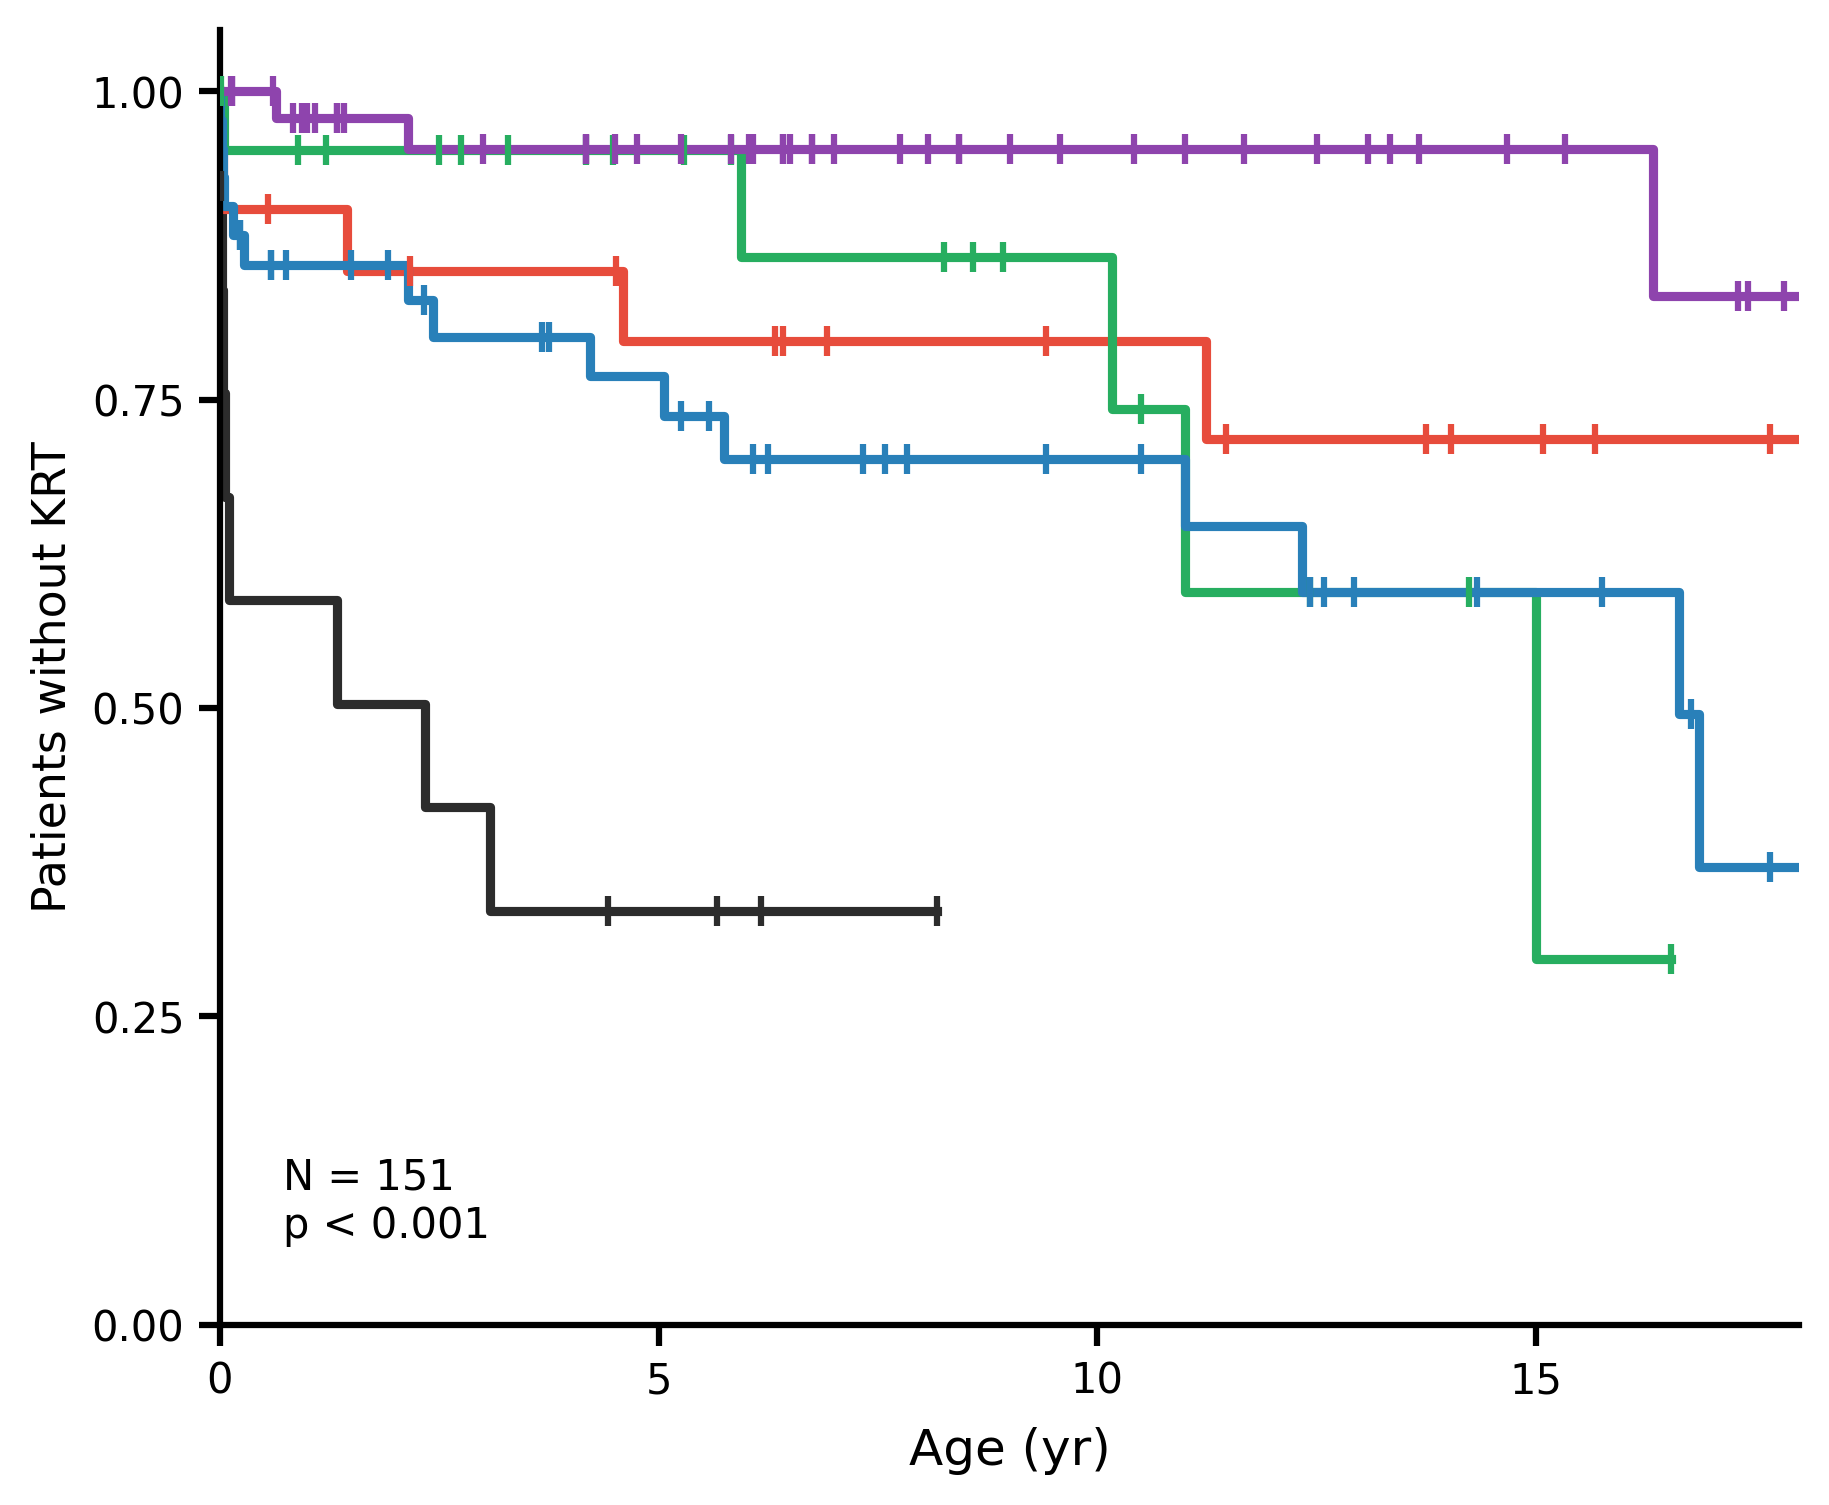

Saved: km_krt.png


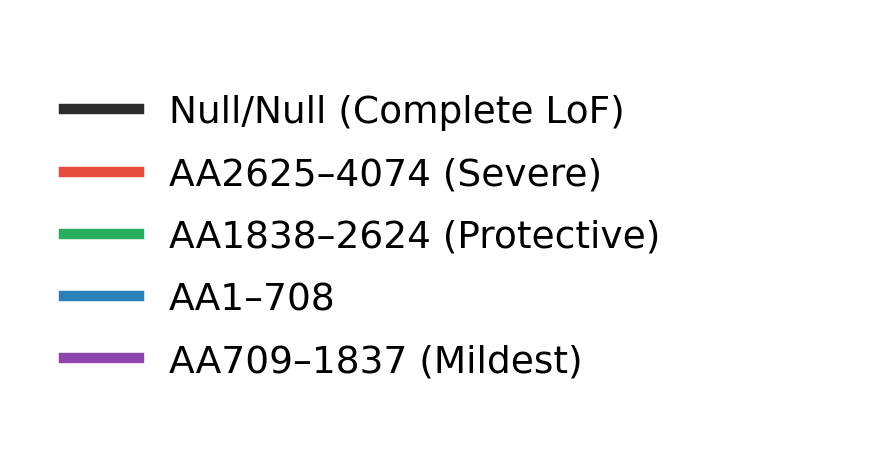

Saved: km_krt_legend.png

───────────────────────────────────────────────────────
STATISTICS — KM_KRT
Overall log-rank: N=151, p < 0.001

Pairwise log-rank:
  Null/Null vs AA2625–4074: p = 0.004
  AA2625–4074 vs AA1838–2624: p = 0.612
  AA1838–2624 vs AA1–708: p = 0.631
  AA1838–2624 vs AA709–1837: p = 0.013

At-risk counts:
  Region                           0     5    10    15
  Null/Null                       13     3     0     0
  AA2625–4074                     21    14    10     6
  AA1838–2624                     22    13     7     2
  AA1–708                         44    24    14     7
  AA709–1837                      51    33    17     9
───────────────────────────────────────────────────────



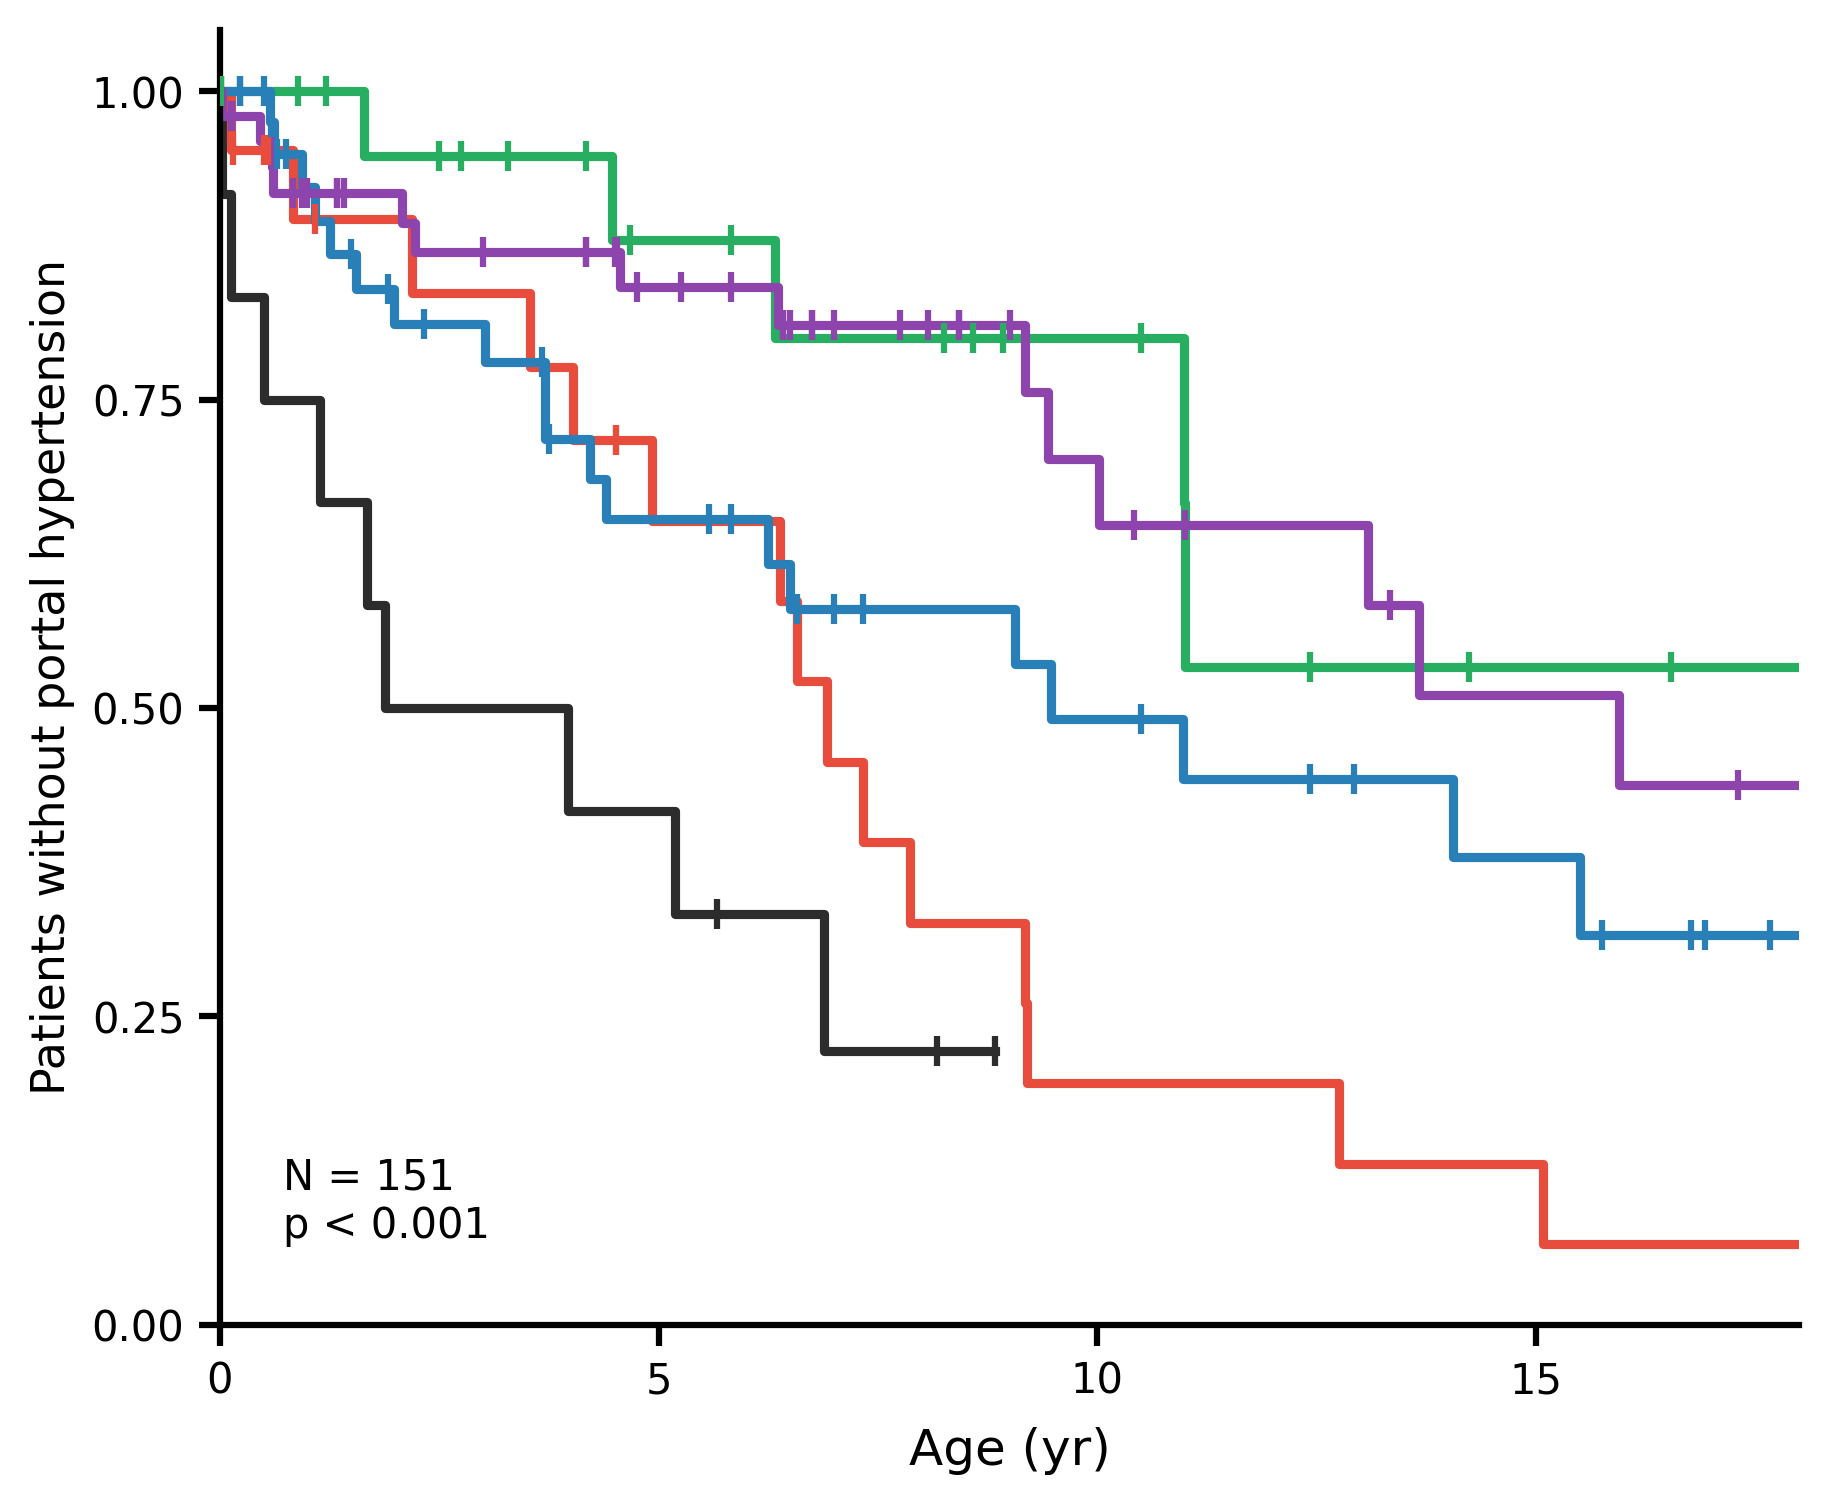

Saved: km_portal_htn.png


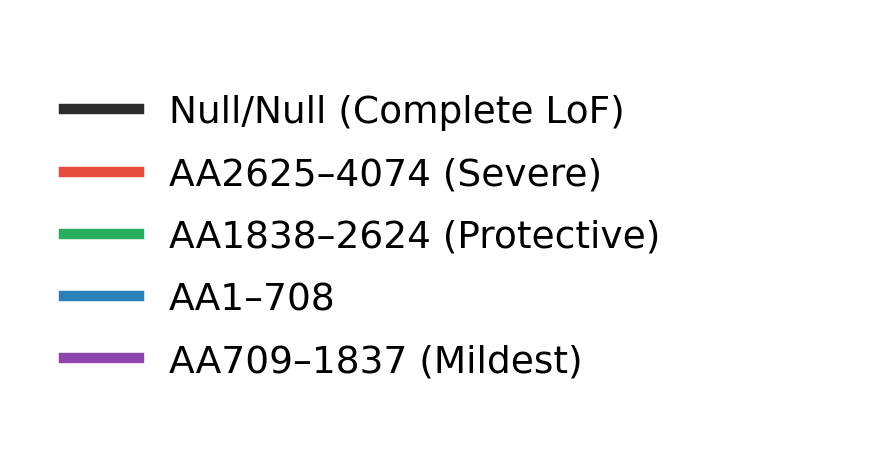

Saved: km_portal_htn_legend.png

───────────────────────────────────────────────────────
STATISTICS — KM_PORTAL_HTN
Overall log-rank: N=151, p < 0.001

Pairwise log-rank:
  Null/Null vs AA2625–4074: p = 0.145
  AA2625–4074 vs AA1838–2624: p = 0.006
  AA1838–2624 vs AA1–708: p = 0.105
  AA1838–2624 vs AA709–1837: p = 0.704

At-risk counts:
  Region                           0     5    10    15
  Null/Null                       13     5     0     0
  AA2625–4074                     21    10     3     2
  AA1838–2624                     22    12     7     2
  AA1–708                         44    20    11     6
  AA709–1837                      51    29    13     7
───────────────────────────────────────────────────────



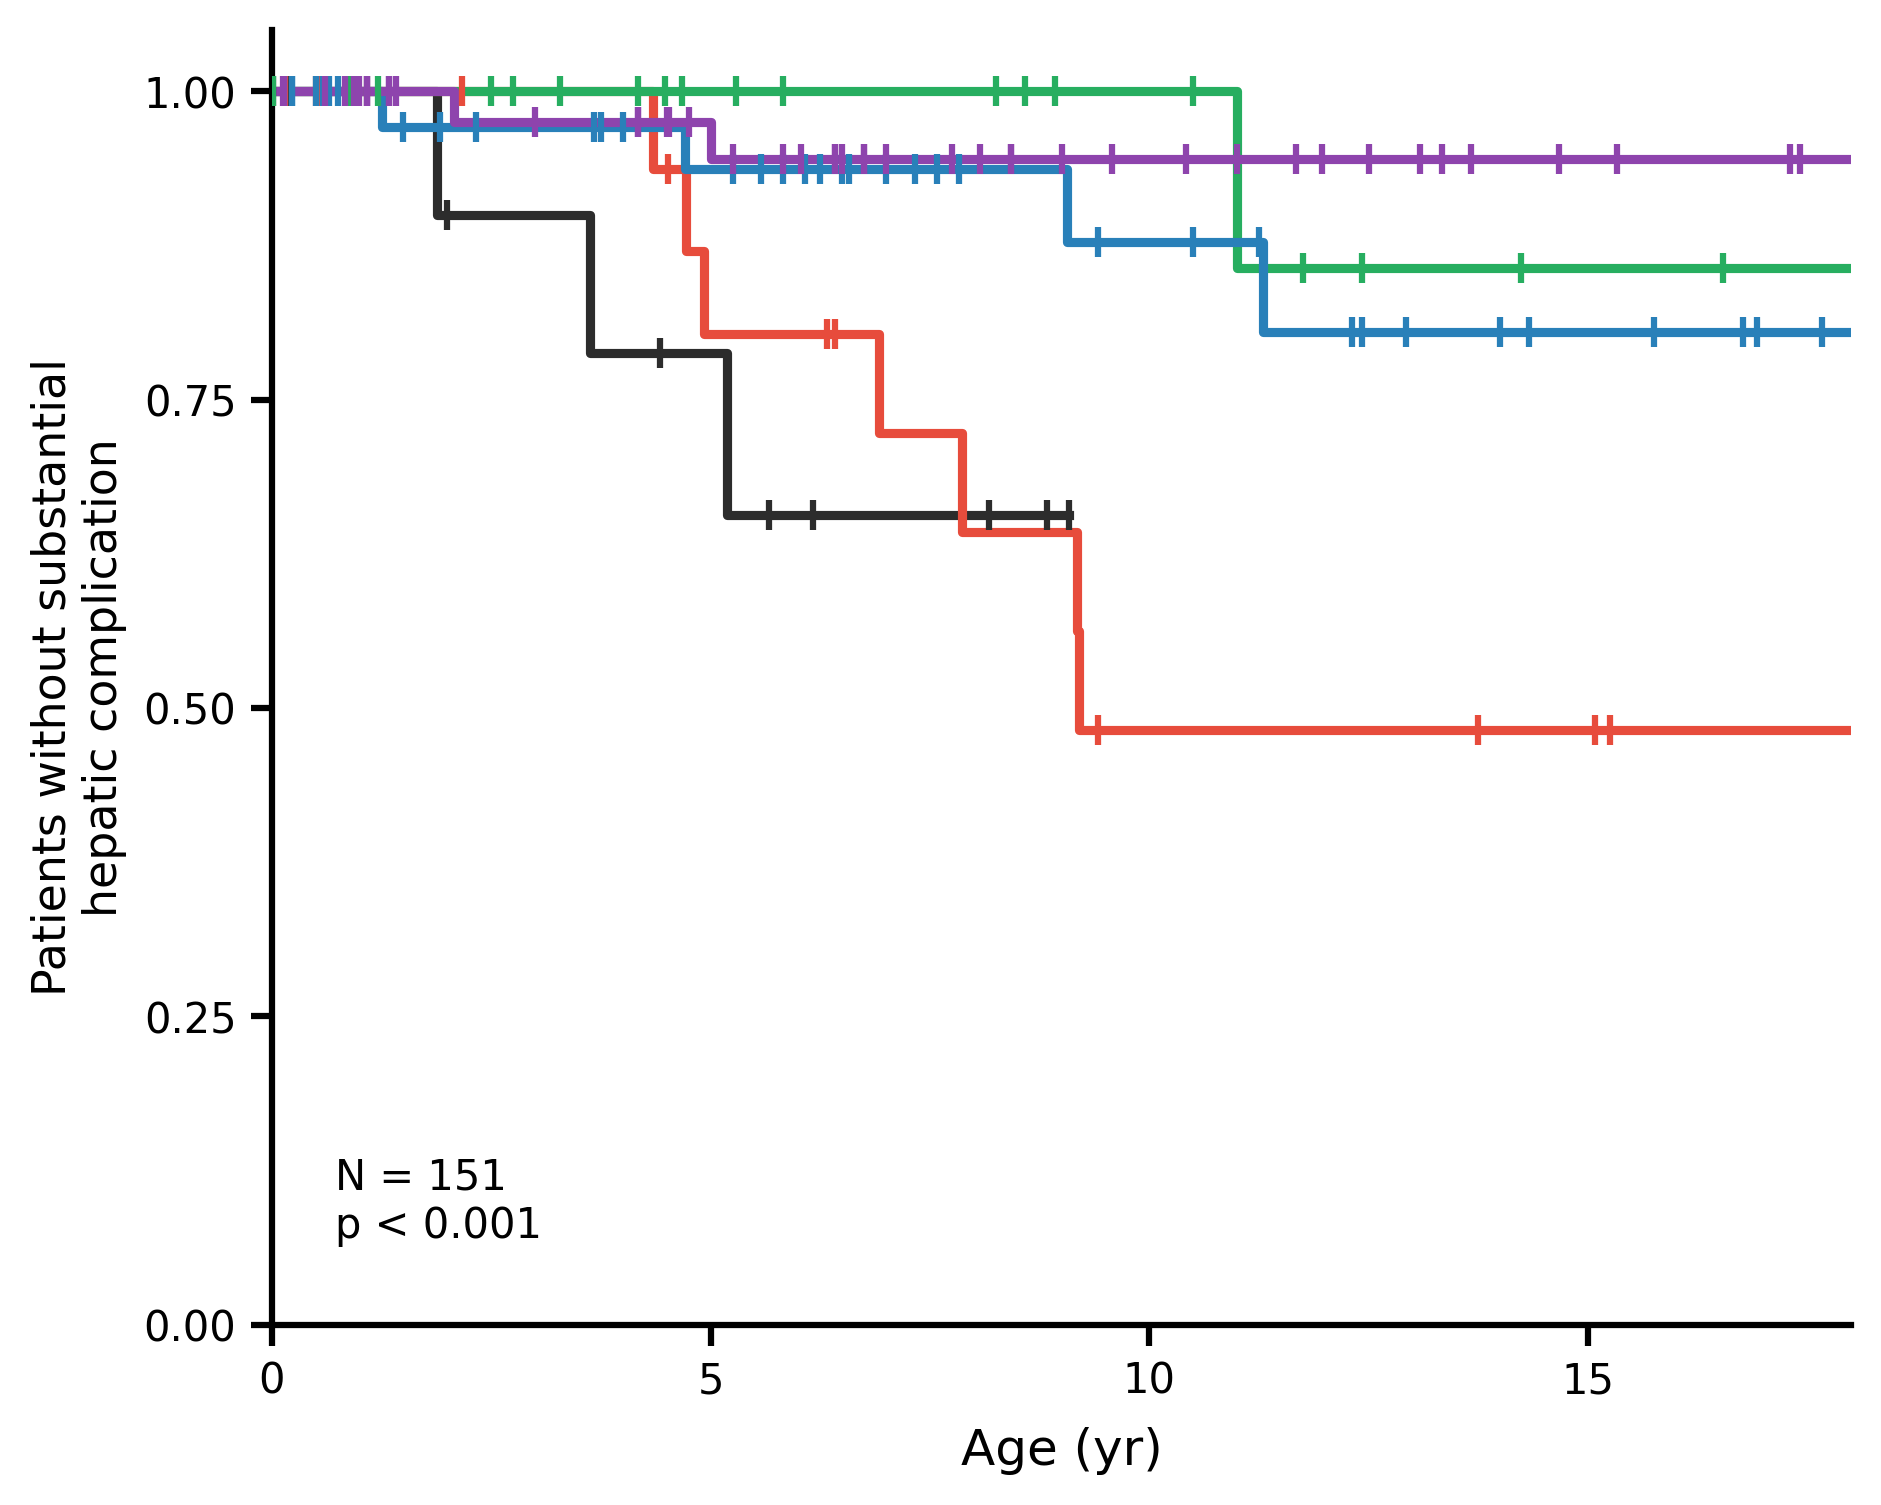

Saved: km_hepatic.png


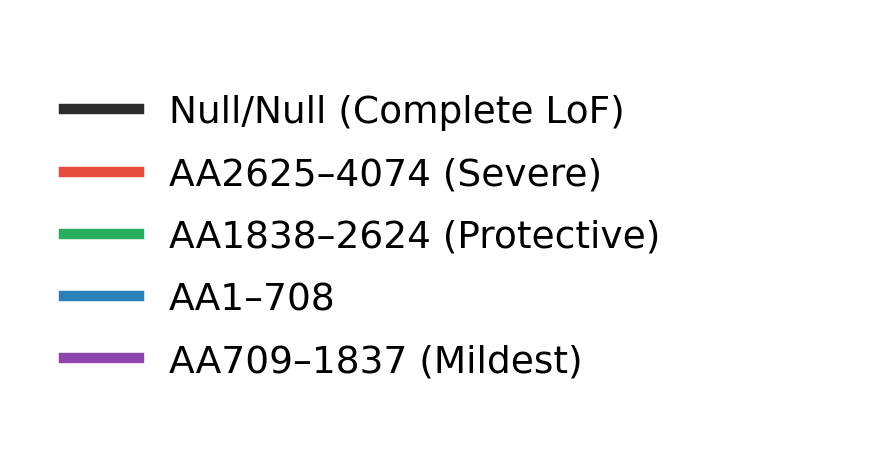

Saved: km_hepatic_legend.png

───────────────────────────────────────────────────────
STATISTICS — KM_HEPATIC
Overall log-rank: N=151, p < 0.001

Pairwise log-rank:
  Null/Null vs AA2625–4074: p = 0.665
  AA2625–4074 vs AA1838–2624: p = 0.019
  AA1838–2624 vs AA1–708: p = 0.516
  AA1838–2624 vs AA709–1837: p = 0.909

At-risk counts:
  Region                           0     5    10    15
  Null/Null                       13     6     0     0
  AA2625–4074                     21    12     5     4
  AA1838–2624                     22    13     8     3
  AA1–708                         44    27    14     6
  AA709–1837                      51    33    17     8
───────────────────────────────────────────────────────



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# ARPKD LoF Severity Ladder — Full Replication Script
# Burgmaier et al. Genotype-Phenotype Analysis
# Requires 5 CSV files (upload to Colab before running)
# ============================================================

# ── 0. Install dependencies ───────────────────────────────────────────────
!pip install lifelines --quiet

# ── 1. Imports ────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
import re

# ── 2. Upload files ───────────────────────────────────────────────────────
# Upload these 5 files when prompted:
#   Burgmaier_Genotype_Phenotype_Replication_-_AA1-708.csv
#   Burgmaier_Genotype_Phenotype_Replication_-_AA709-1837.csv
#   Burgmaier_Genotype_Phenotype_Replication_-_AA1838-2624.csv
#   Burgmaier_Genotype_Phenotype_Replication_-_AA2625-4074.csv
#   Burgmaier_Genotype_Phenotype_Replication_-_Null_Null.csv

from google.colab import files
uploaded = files.upload()

# ── 3. Helper functions ───────────────────────────────────────────────────

def is_missense(variant):
    v = variant.strip()
    if not v.startswith('p.'):
        return False
    if any(x in v for x in ['*', 'fs', 'del', 'dup', 'ins', '?', 'ext', 'Ter']):
        return False
    return bool(re.match(r'p\.[A-Z][a-z]{2}\d+[A-Z][a-z]{2}$', v))

def to_numeric(col):
    return pd.to_numeric(col, errors='coerce')

def prepare_survival(df, event_col, age_col, followup_col='followup_age'):
    duration = np.where(df[event_col] == 1, df[age_col], df[followup_col])
    duration = np.where((duration <= 0) & (df[event_col].values == 0),
                        np.nan, duration)
    duration = np.where(duration <= 0, 0.001, duration)
    mask     = ~np.isnan(duration)
    return duration[mask].astype(float), df[event_col].values[mask].astype(int)

def fmt_p(p):
    if p < 0.001: return 'p < 0.001'
    return f'p = {p:.3f}'

# ── 4. Load regional files ────────────────────────────────────────────────

regional_files = {
    'AA1_708':     'Burgmaier_Genotype_Phenotype_Replication - AA1-708.csv',
    'AA709_1837':  'Burgmaier_Genotype_Phenotype_Replication - AA709-1837.csv',
    'AA1838_2624': 'Burgmaier_Genotype_Phenotype_Replication - AA1838-2624.csv',
    'AA2625_4074': 'Burgmaier_Genotype_Phenotype_Replication - AA2625-4074.csv',
}

dfs = []
for region, fname in regional_files.items():
    df = pd.read_csv(fname)
    df['region'] = region
    dfs.append(df)

regional_data = pd.concat(dfs, ignore_index=True)

# ── 5. Extract missense variants per functional class ─────────────────────

missense_variants = {}
for region, fname in regional_files.items():
    df       = pd.read_csv(fname)
    variants = []
    for entry in df['Predicted protein change'].dropna():
        for v in entry.split(';'):
            if is_missense(v.strip()):
                variants.append(v.strip())
    missense_variants[region] = sorted(set(variants))

missense_AA1_708     = missense_variants['AA1_708']
missense_AA709_1837  = missense_variants['AA709_1837']
missense_AA1838_2624 = missense_variants['AA1838_2624']
missense_AA2625_4074 = missense_variants['AA2625_4074']

print("Missense variant counts per region:")
for region, vlist in missense_variants.items():
    print(f"  {region}: {len(vlist)} unique missense variants")

# ── 6. Parse clinical outcomes from regional files ────────────────────────

def parse_regional(df, region):
    df = df.copy()
    df['region']        = region
    df['krt_age']       = to_numeric(df.iloc[:, 2])
    df['portal_htn_age']= to_numeric(df.iloc[:, 3])
    df['hepatic_age']   = to_numeric(df.iloc[:, 4])
    df['followup_age']  = to_numeric(
        df.iloc[:, 5].astype(str).str.extract(r'([\d.]+)')[0])
    df['had_krt']        = df['krt_age'].notna().astype(int)
    df['had_portal_htn'] = df['portal_htn_age'].notna().astype(int)
    df['had_hepatic']    = df['hepatic_age'].notna().astype(int)
    df['hepatic_only']   = ((df['had_hepatic']==1) & (df['had_krt']==0)).astype(int)
    df['renal_only']     = ((df['had_krt']==1)     & (df['had_hepatic']==0)).astype(int)
    df['both_events']    = ((df['had_krt']==1)     & (df['had_hepatic']==1)).astype(int)
    df['no_events']      = ((df['had_krt']==0)     & (df['had_hepatic']==0)).astype(int)
    return df

regional_parsed = []
for region, fname in regional_files.items():
    df = pd.read_csv(fname)
    regional_parsed.append(parse_regional(df, region))

data = pd.concat(regional_parsed, ignore_index=True)

# ── 7. Load and parse Null/Null ───────────────────────────────────────────

null_null = pd.read_csv('Burgmaier_Genotype_Phenotype_Replication - Null_Null.csv')
null_null['region']         = 'Null_Null'
null_null['krt_age']        = to_numeric(null_null['KRT (age at onset, yrs)'])
null_null['portal_htn_age'] = to_numeric(null_null['Portal HTN during disease course (age, yrs)'])
null_null['hepatic_age']    = to_numeric(null_null['Substan- tial hepatic compli- cation during disease course (age, yrs)'])
null_null['followup_age']   = to_numeric(
    null_null['Last follow- up (age, yrs), Death'].astype(str).str.extract(r'([\d.]+)')[0])
null_null['had_krt']        = null_null['krt_age'].notna().astype(int)
null_null['had_portal_htn'] = null_null['portal_htn_age'].notna().astype(int)
null_null['had_hepatic']    = null_null['hepatic_age'].notna().astype(int)
null_null['hepatic_only']   = ((null_null['had_hepatic']==1) & (null_null['had_krt']==0)).astype(int)
null_null['renal_only']     = ((null_null['had_krt']==1)     & (null_null['had_hepatic']==0)).astype(int)
null_null['both_events']    = ((null_null['had_krt']==1)     & (null_null['had_hepatic']==1)).astype(int)
null_null['no_events']      = ((null_null['had_krt']==0)     & (null_null['had_hepatic']==0)).astype(int)

# ── 8. Combine all groups ─────────────────────────────────────────────────

cols = ['region', 'had_krt', 'had_portal_htn', 'had_hepatic',
        'hepatic_only', 'renal_only', 'both_events', 'no_events',
        'krt_age', 'portal_htn_age', 'hepatic_age', 'followup_age']

combined = pd.concat([data[cols], null_null[cols]], ignore_index=True)

print(f"\nCombined dataset: {len(combined)} patients")
print(combined.groupby('region').size().to_string())

# ── 9. Organ selectivity analysis ─────────────────────────────────────────

import scipy.stats as stats

summary = combined.groupby('region').agg(
    n                 = ('region', 'count'),
    krt_rate          = ('had_krt', 'mean'),
    portal_htn_rate   = ('had_portal_htn', 'mean'),
    hepatic_rate      = ('had_hepatic', 'mean'),
    hepatic_only_rate = ('hepatic_only', 'mean'),
    renal_only_rate   = ('renal_only', 'mean'),
    both_rate         = ('both_events', 'mean'),
    no_events_rate    = ('no_events', 'mean'),
).round(3)

print("\n── Event rates by region ──")
print(summary.to_string())

print("\n── Fisher's Exact: AA1838_2624 vs AA2625_4074 ──")
protective = combined[combined['region'] == 'AA1838_2624']
severe     = combined[combined['region'] == 'AA2625_4074']
for event, label in [('had_hepatic',    'Hepatic complication'),
                     ('had_portal_htn', 'Portal hypertension'),
                     ('had_krt',        'KRT')]:
    a     = protective[event].values
    b     = severe[event].values
    table = [[sum(a==1), sum(a==0)], [sum(b==1), sum(b==0)]]
    OR, p = stats.fisher_exact(table)
    print(f"  {label:<28} OR={OR:.2f}  {fmt_p(p)}  {'*' if p<0.05 else 'ns'}")

print("\n── Fisher's Exact: Null/Null vs AA2625_4074 ──")
nn  = combined[combined['region'] == 'Null_Null']
sev = combined[combined['region'] == 'AA2625_4074']
for event, label in [('had_hepatic',    'Hepatic complication'),
                     ('had_portal_htn', 'Portal hypertension'),
                     ('had_krt',        'KRT')]:
    a     = nn[event].values
    b     = sev[event].values
    table = [[sum(a==1), sum(a==0)], [sum(b==1), sum(b==0)]]
    OR, p = stats.fisher_exact(table)
    print(f"  {label:<28} OR={OR:.2f}  {fmt_p(p)}  {'*' if p<0.05 else 'ns'}")

# ── 10. KM plots ──────────────────────────────────────────────────────────

plt.rcParams.update({
    'font.family':       'DejaVu Sans',
    'font.size':         11,
    'axes.linewidth':    1.5,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'xtick.major.width': 1.5,
    'ytick.major.width': 1.5,
    'xtick.major.size':  5,
    'ytick.major.size':  5,
    'figure.dpi':        300,
    'figure.facecolor':  'none',
    'axes.facecolor':    'none',
})

ladder  = ['Null_Null', 'AA2625_4074', 'AA1838_2624', 'AA1_708', 'AA709_1837']
labels  = ['Null/Null (Complete LoF)', 'AA2625–4074 (Severe)',
           'AA1838–2624 (Protective)', 'AA1–708', 'AA709–1837 (Mildest)']
colors  = ['#2c2c2c', '#e74c3c', '#27ae60', '#2980b9', '#8e44ad']

km_pairs = [
    ('Null_Null',   'AA2625_4074', 'Null/Null vs AA2625–4074'),
    ('AA2625_4074', 'AA1838_2624', 'AA2625–4074 vs AA1838–2624'),
    ('AA1838_2624', 'AA1_708',     'AA1838–2624 vs AA1–708'),
    ('AA1838_2624', 'AA709_1837',  'AA1838–2624 vs AA709–1837'),
]

endpoints = [
    ('had_krt',        'krt_age',
     'Patients without KRT',                               'km_krt'),
    ('had_portal_htn', 'portal_htn_age',
     'Patients without portal hypertension',               'km_portal_htn'),
    ('had_hepatic',    'hepatic_age',
     'Patients without substantial\nhepatic complication', 'km_hepatic'),
]

timepoints = [0, 5, 10, 15]

for (event_col, age_col, ylabel, fname_base) in endpoints:

    # ── KM plot ───────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(6.5, 5.2))
    fig.patch.set_alpha(0)
    ax.patch.set_alpha(0)
    fig.subplots_adjust(left=0.16, right=0.97, top=0.96, bottom=0.13)

    n_total = 0
    for region, label, color in zip(ladder, labels, colors):
        subset   = combined[combined['region'] == region].copy()
        n_total += len(subset)
        duration, event = prepare_survival(subset, event_col, age_col)
        kmf = KaplanMeierFitter()
        kmf.fit(duration, event_observed=event)
        kmf.plot_survival_function(
            ax=ax, ci_show=False, color=color,
            linewidth=2.2, label=label,
        )
        # ── Censoring ticks ───────────────────────────────────────────────
        censored_times = duration[event == 0]
        if len(censored_times) > 0:
            censored_probs = kmf.survival_function_at_times(censored_times).values
            ax.scatter(
                censored_times, censored_probs,
                marker='|', color=color,
                s=50, linewidth=1.5, zorder=5,
            )

    # Overall log-rank
    durations_all, events_all, groups_all = [], [], []
    for region in ladder:
        subset = combined[combined['region'] == region].copy()
        d, e   = prepare_survival(subset, event_col, age_col)
        durations_all.extend(d)
        events_all.extend(e)
        groups_all.extend([region] * len(d))
    result = multivariate_logrank_test(durations_all, groups_all, events_all)

    ax.text(0.04, 0.06, f'N = {n_total}\n{fmt_p(result.p_value)}',
            transform=ax.transAxes, fontsize=10, va='bottom')

    leg = ax.get_legend()
    if leg: leg.remove()

    ax.set_xlim(0, 18)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('Age (yr)', fontsize=12, labelpad=6)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_xticks([0, 5, 10, 15])
    ax.set_yticks([0.00, 0.25, 0.50, 0.75, 1.00])
    ax.yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, _: f'{x:.2f}'))
    ax.tick_params(axis='both', labelsize=10)

    plt.savefig(f'{fname_base}.png', dpi=300,
                bbox_inches='tight', transparent=True)
    plt.show()
    print(f'Saved: {fname_base}.png')

    # ── Legend PNG ────────────────────────────────────────────────────────
    fig_leg, ax_leg = plt.subplots(figsize=(3.5, 1.8))
    fig_leg.patch.set_alpha(0)
    ax_leg.patch.set_alpha(0)
    ax_leg.axis('off')
    handles = [plt.Line2D([0], [0], color=c, linewidth=2.5) for c in colors]
    ax_leg.legend(handles, labels, loc='center left',
                  fontsize=9, frameon=False,
                  handlelength=2.0, labelspacing=0.7)
    plt.savefig(f'{fname_base}_legend.png', dpi=300,
                bbox_inches='tight', transparent=True)
    plt.show()
    print(f'Saved: {fname_base}_legend.png')

    # ── Print stats ───────────────────────────────────────────────────────
    print(f'\n{"─"*55}')
    print(f'STATISTICS — {fname_base.upper()}')
    print(f'Overall log-rank: N={n_total}, {fmt_p(result.p_value)}')
    print('\nPairwise log-rank:')
    for r1, r2, plabel in km_pairs:
        s1 = combined[combined['region'] == r1]
        s2 = combined[combined['region'] == r2]
        d1, e1 = prepare_survival(s1, event_col, age_col)
        d2, e2 = prepare_survival(s2, event_col, age_col)
        lr = logrank_test(d1, d2, e1, e2)
        print(f'  {plabel}: {fmt_p(lr.p_value)}')

    print('\nAt-risk counts:')
    header = f"  {'Region':<28}" + ''.join(f'{t:>6}' for t in timepoints)
    print(header)
    for region, label in zip(ladder, labels):
        subset    = combined[combined['region'] == region].copy()
        n_total_r = len(subset)
        duration, event = prepare_survival(subset, event_col, age_col)
        counts = [n_total_r if t == 0 else int(np.sum(duration >= t))
                  for t in timepoints]
        short = label.split('(')[0].strip()
        print(f"  {short:<28}" + ''.join(f'{c:>6}' for c in counts))
    print(f'{"─"*55}\n')

# ── 11. Download all output files ─────────────────────────────────────────
for fname in ['km_krt.png',        'km_krt_legend.png',
              'km_portal_htn.png', 'km_portal_htn_legend.png',
              'km_hepatic.png',    'km_hepatic_legend.png']:
    files.download(fname)

# **Effects of Trans-Heterozygotes**

In [ ]:
# ── Load full 304 dataset ──────────────────────────────────────────────────
full = pd.read_csv('/content/Trans-Heterozygotes - Original - Burgmaier et al (304) (1).csv')

# ── Verify exact labels ────────────────────────────────────────────────────
print("All functional class values:")
print(full['Functional class'].value_counts().to_string())

# ── Extract trans-heterozygote groups ──────────────────────────────────────
trans_groups = {}
for label in full['Functional class'].unique():
    if '2625' in str(label) and '/' in str(label):
        trans_groups[label] = label

print("\nGroups containing AA2625-4074 allele:")
for k in trans_groups:
    print(f"  repr: {repr(k)}")

All functional class values:
Functional class
Single variant                53
Null/ Mis709-1837             35
Others                        28
Null/ Mis1-708                26
Mis1-708/ Mis1-708            18
Mis1-708/ Mis2625-4074        17
Null/ Mis1838-2624            17
Mis1-708/ Mis709-1837         16
Mis709-1837/ Mis709-1837      16
Null/Null                     13
Mis709-1837/ Mis2625-4074     13
Mis2625-4074/ Mis2625-4074    12
Mis1-708/ Mis1838-2624        11
Null/ Mis2625-4074             9
Mis1838-2624/ Mis2625-4074     8
Mis709-1837/ Mis1838-2624      7
Mis1838-2624/ Mis1838-2624     5

Groups containing AA2625-4074 allele:
  repr: 'Mis2625-4074/ Mis2625-4074'
  repr: 'Mis1-708/ Mis2625-4074'
  repr: 'Null/ Mis2625-4074'
  repr: 'Mis709-1837/ Mis2625-4074'
  repr: 'Mis1838-2624/ Mis2625-4074'


In [ ]:
# ── Extract trans-heterozygote groups from full 304 dataset ───────────────

trans_groups = {
    'Mis1838_Mis2625': 'Mis1838-2624/ Mis2625-4074',   # n=8  rescue
    'Mis1_708_Mis2625': 'Mis1-708/ Mis2625-4074',       # n=17
    'Mis709_Mis2625':  'Mis709-1837/ Mis2625-4074',     # n=13
}

trans_parsed = []
for region_key, group_label in trans_groups.items():
    subset = full[full['Functional class'] == group_label].copy()
    subset['region']         = region_key
    subset['krt_age']        = to_numeric(subset['KRT (age at onset, yrs)'])
    subset['portal_htn_age'] = to_numeric(subset['Portal HTN during disease course (age, yrs)'])
    subset['hepatic_age']    = to_numeric(subset['Substan- tial hepatic compli- cation during disease course (age, yrs)'])
    subset['followup_age']   = to_numeric(
        subset['Last follow- up (age, yrs), Death'].astype(str).str.extract(r'([\d.]+)')[0])
    subset['had_krt']        = subset['krt_age'].notna().astype(int)
    subset['had_portal_htn'] = subset['portal_htn_age'].notna().astype(int)
    subset['had_hepatic']    = subset['hepatic_age'].notna().astype(int)
    subset['hepatic_only']   = ((subset['had_hepatic']==1) & (subset['had_krt']==0)).astype(int)
    subset['renal_only']     = ((subset['had_krt']==1)     & (subset['had_hepatic']==0)).astype(int)
    subset['both_events']    = ((subset['had_krt']==1)     & (subset['had_hepatic']==1)).astype(int)
    subset['no_events']      = ((subset['had_krt']==0)     & (subset['had_hepatic']==0)).astype(int)
    print(f"{group_label}: n={len(subset)}")
    trans_parsed.append(subset[cols])

# ── Append to combined ────────────────────────────────────────────────────
combined = pd.concat([combined] + trans_parsed, ignore_index=True)

print(f"\nUpdated combined: {len(combined)} patients")
print(combined.groupby('region').size().to_string())



Mis1838-2624/ Mis2625-4074: n=8
Mis1-708/ Mis2625-4074: n=17
Mis709-1837/ Mis2625-4074: n=13

Updated combined: 189 patients
region
AA1838_2624         22
AA1_708             44
AA2625_4074         21
AA709_1837          51
Mis1838_Mis2625      8
Mis1_708_Mis2625    17
Mis709_Mis2625      13
Null_Null           13


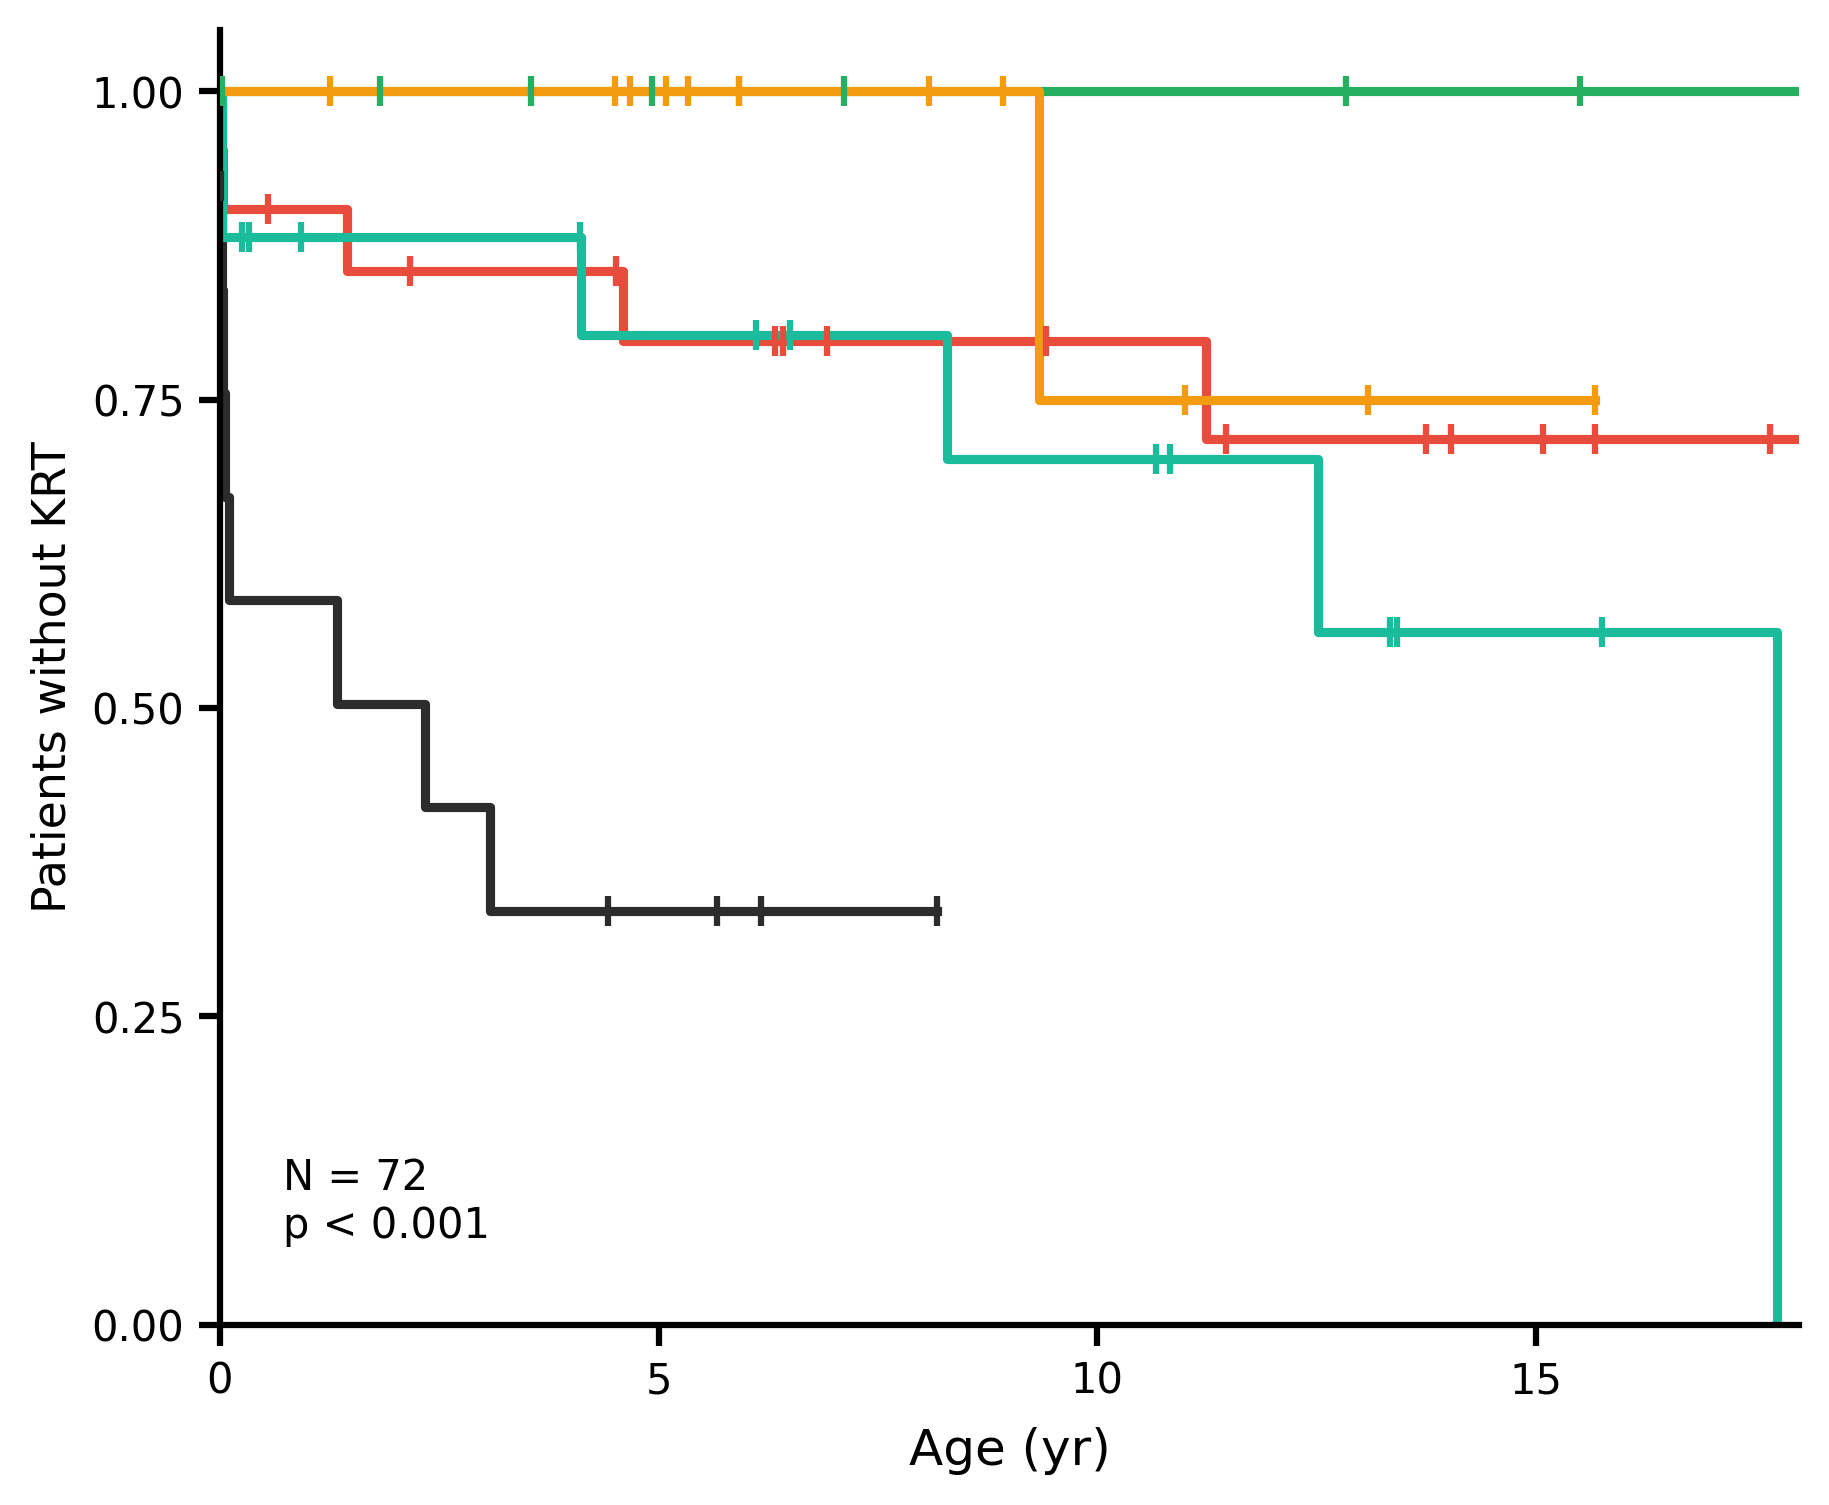

Saved: km_krt.png


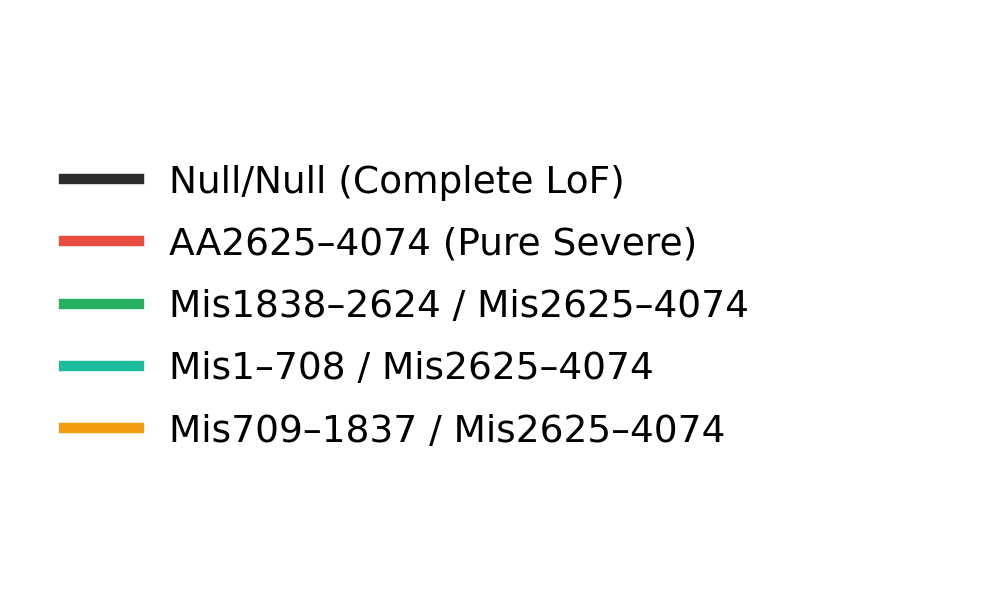

Saved: km_krt_legend.png

───────────────────────────────────────────────────────
STATISTICS — KM_KRT
Overall log-rank: N=72, p < 0.001

Pairwise log-rank:
  Null/Null vs AA2625–4074: p = 0.004
  AA2625–4074 vs Mis1838/Mis2625: p = 0.149
  AA2625–4074 vs Mis1-708/Mis2625: p = 0.300
  AA2625–4074 vs Mis709/Mis2625: p = 0.364
  Null/Null vs Mis1838/Mis2625: p = 0.009

At-risk counts:
  Region                                  0     5    10    15
  Null/Null                              13     3     0     0
  AA2625–4074                            21    14    10     6
  Mis1838–2624 / Mis2625–4074             8     4     3     2
  Mis1–708 / Mis2625–4074                17    10     7     2
  Mis709–1837 / Mis2625–4074             13    10     3     1
───────────────────────────────────────────────────────



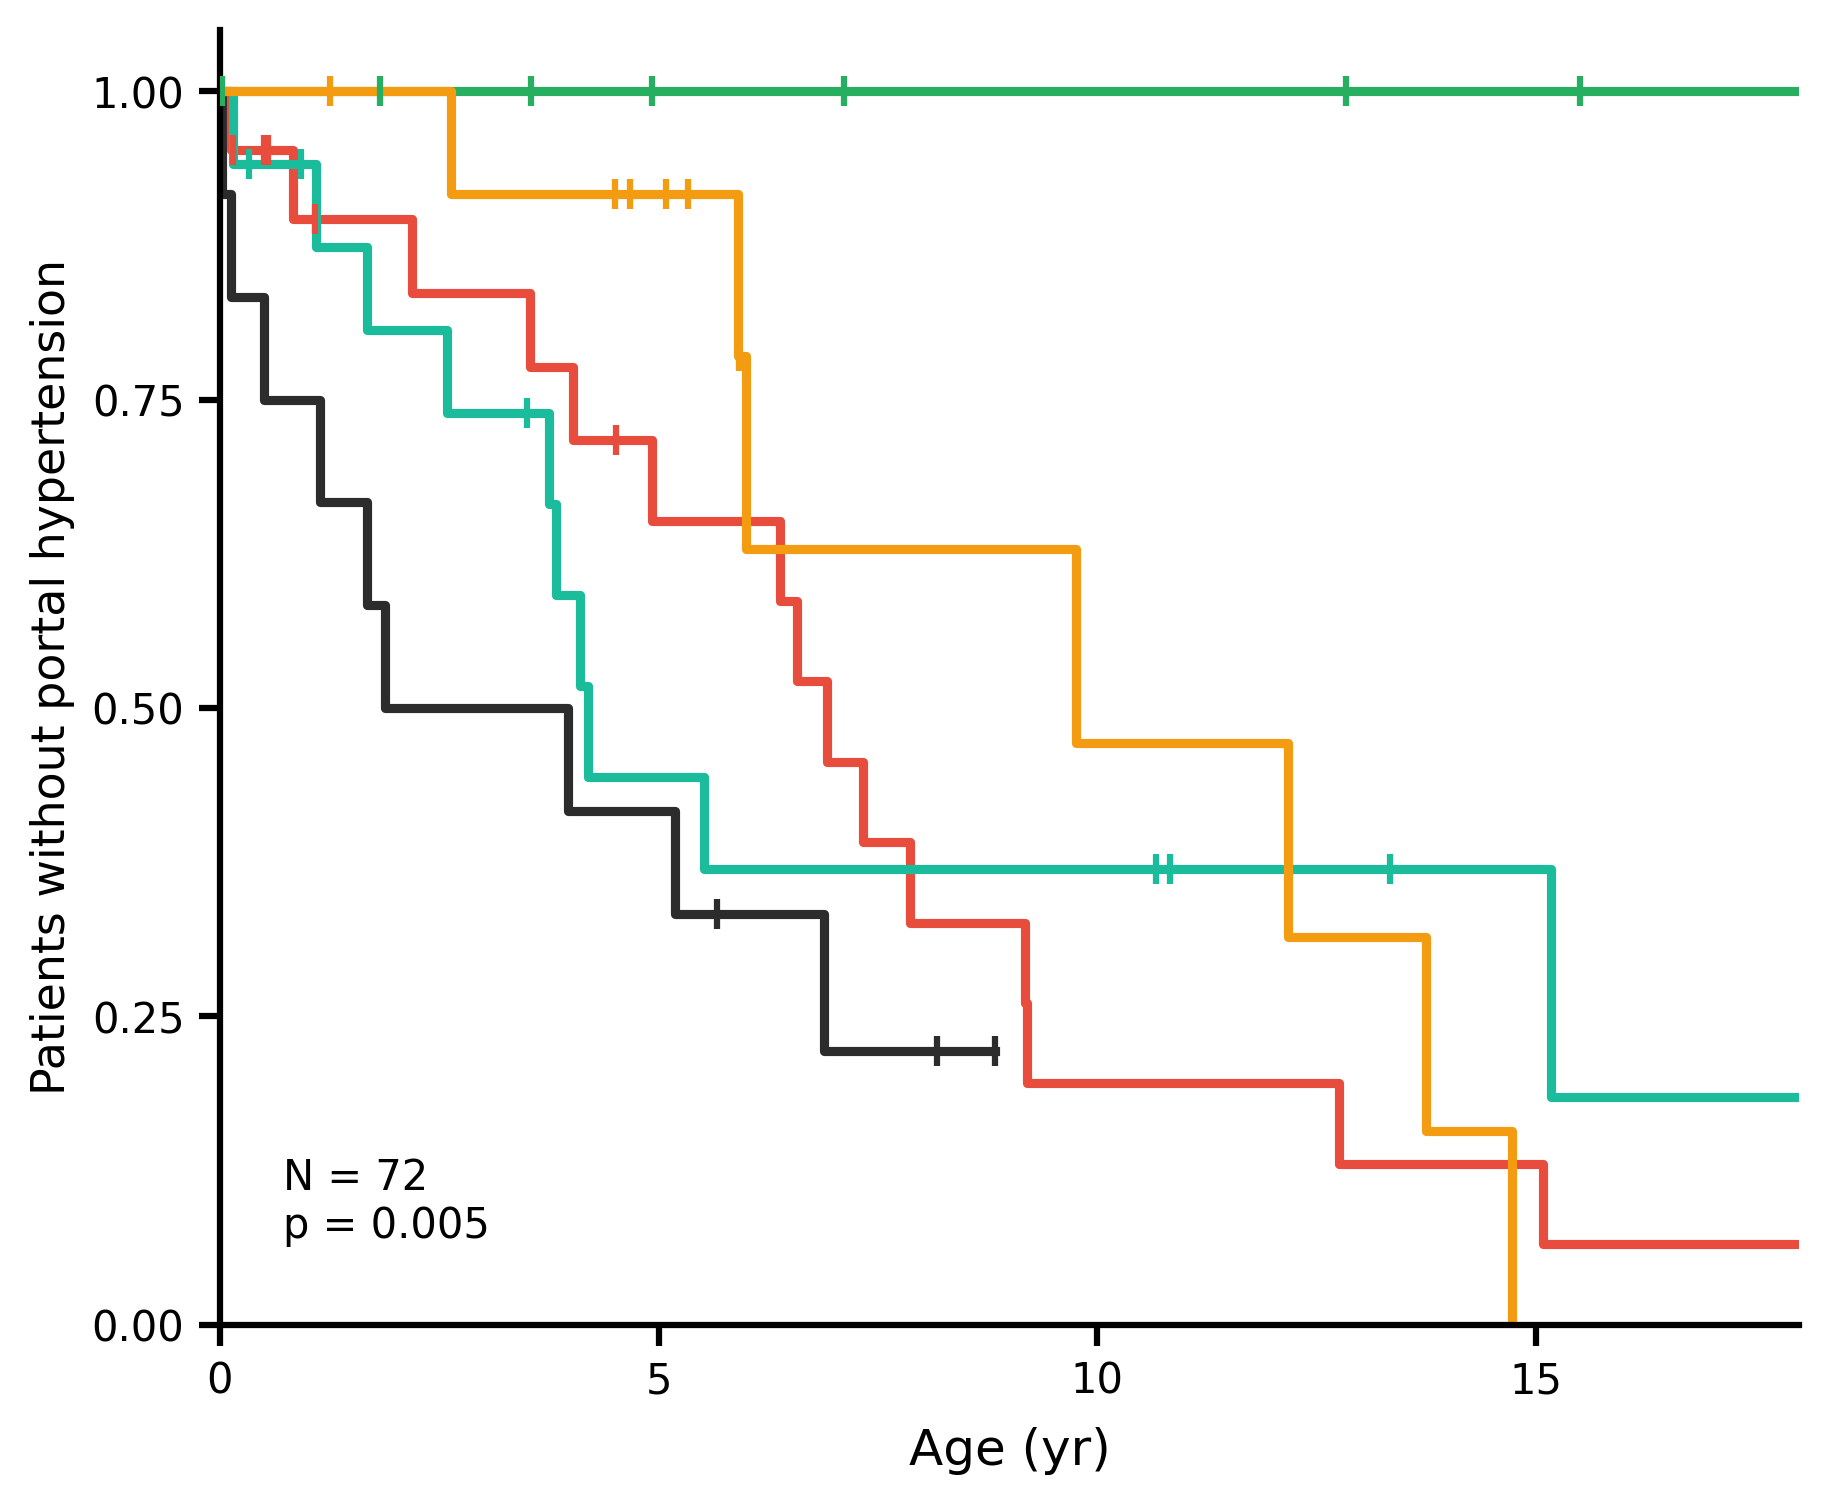

Saved: km_portal_htn.png


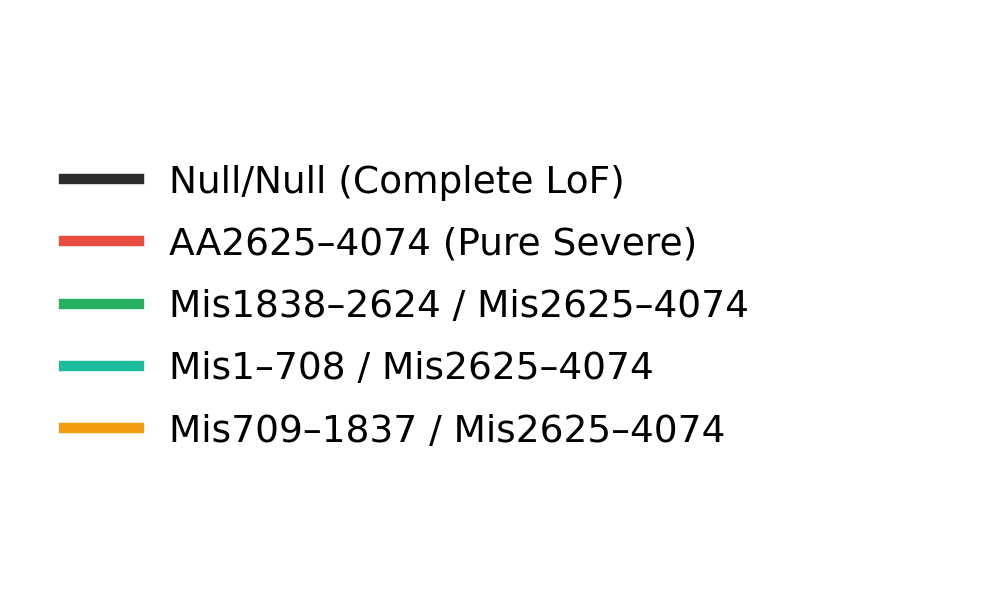

Saved: km_portal_htn_legend.png

───────────────────────────────────────────────────────
STATISTICS — KM_PORTAL_HTN
Overall log-rank: N=72, p = 0.005

Pairwise log-rank:
  Null/Null vs AA2625–4074: p = 0.145
  AA2625–4074 vs Mis1838/Mis2625: p = 0.003
  AA2625–4074 vs Mis1-708/Mis2625: p = 0.540
  AA2625–4074 vs Mis709/Mis2625: p = 0.433
  Null/Null vs Mis1838/Mis2625: p = 0.007

At-risk counts:
  Region                                  0     5    10    15
  Null/Null                              13     5     0     0
  AA2625–4074                            21    10     3     2
  Mis1838–2624 / Mis2625–4074             8     4     3     2
  Mis1–708 / Mis2625–4074                17     6     5     2
  Mis709–1837 / Mis2625–4074             13     9     3     0
───────────────────────────────────────────────────────



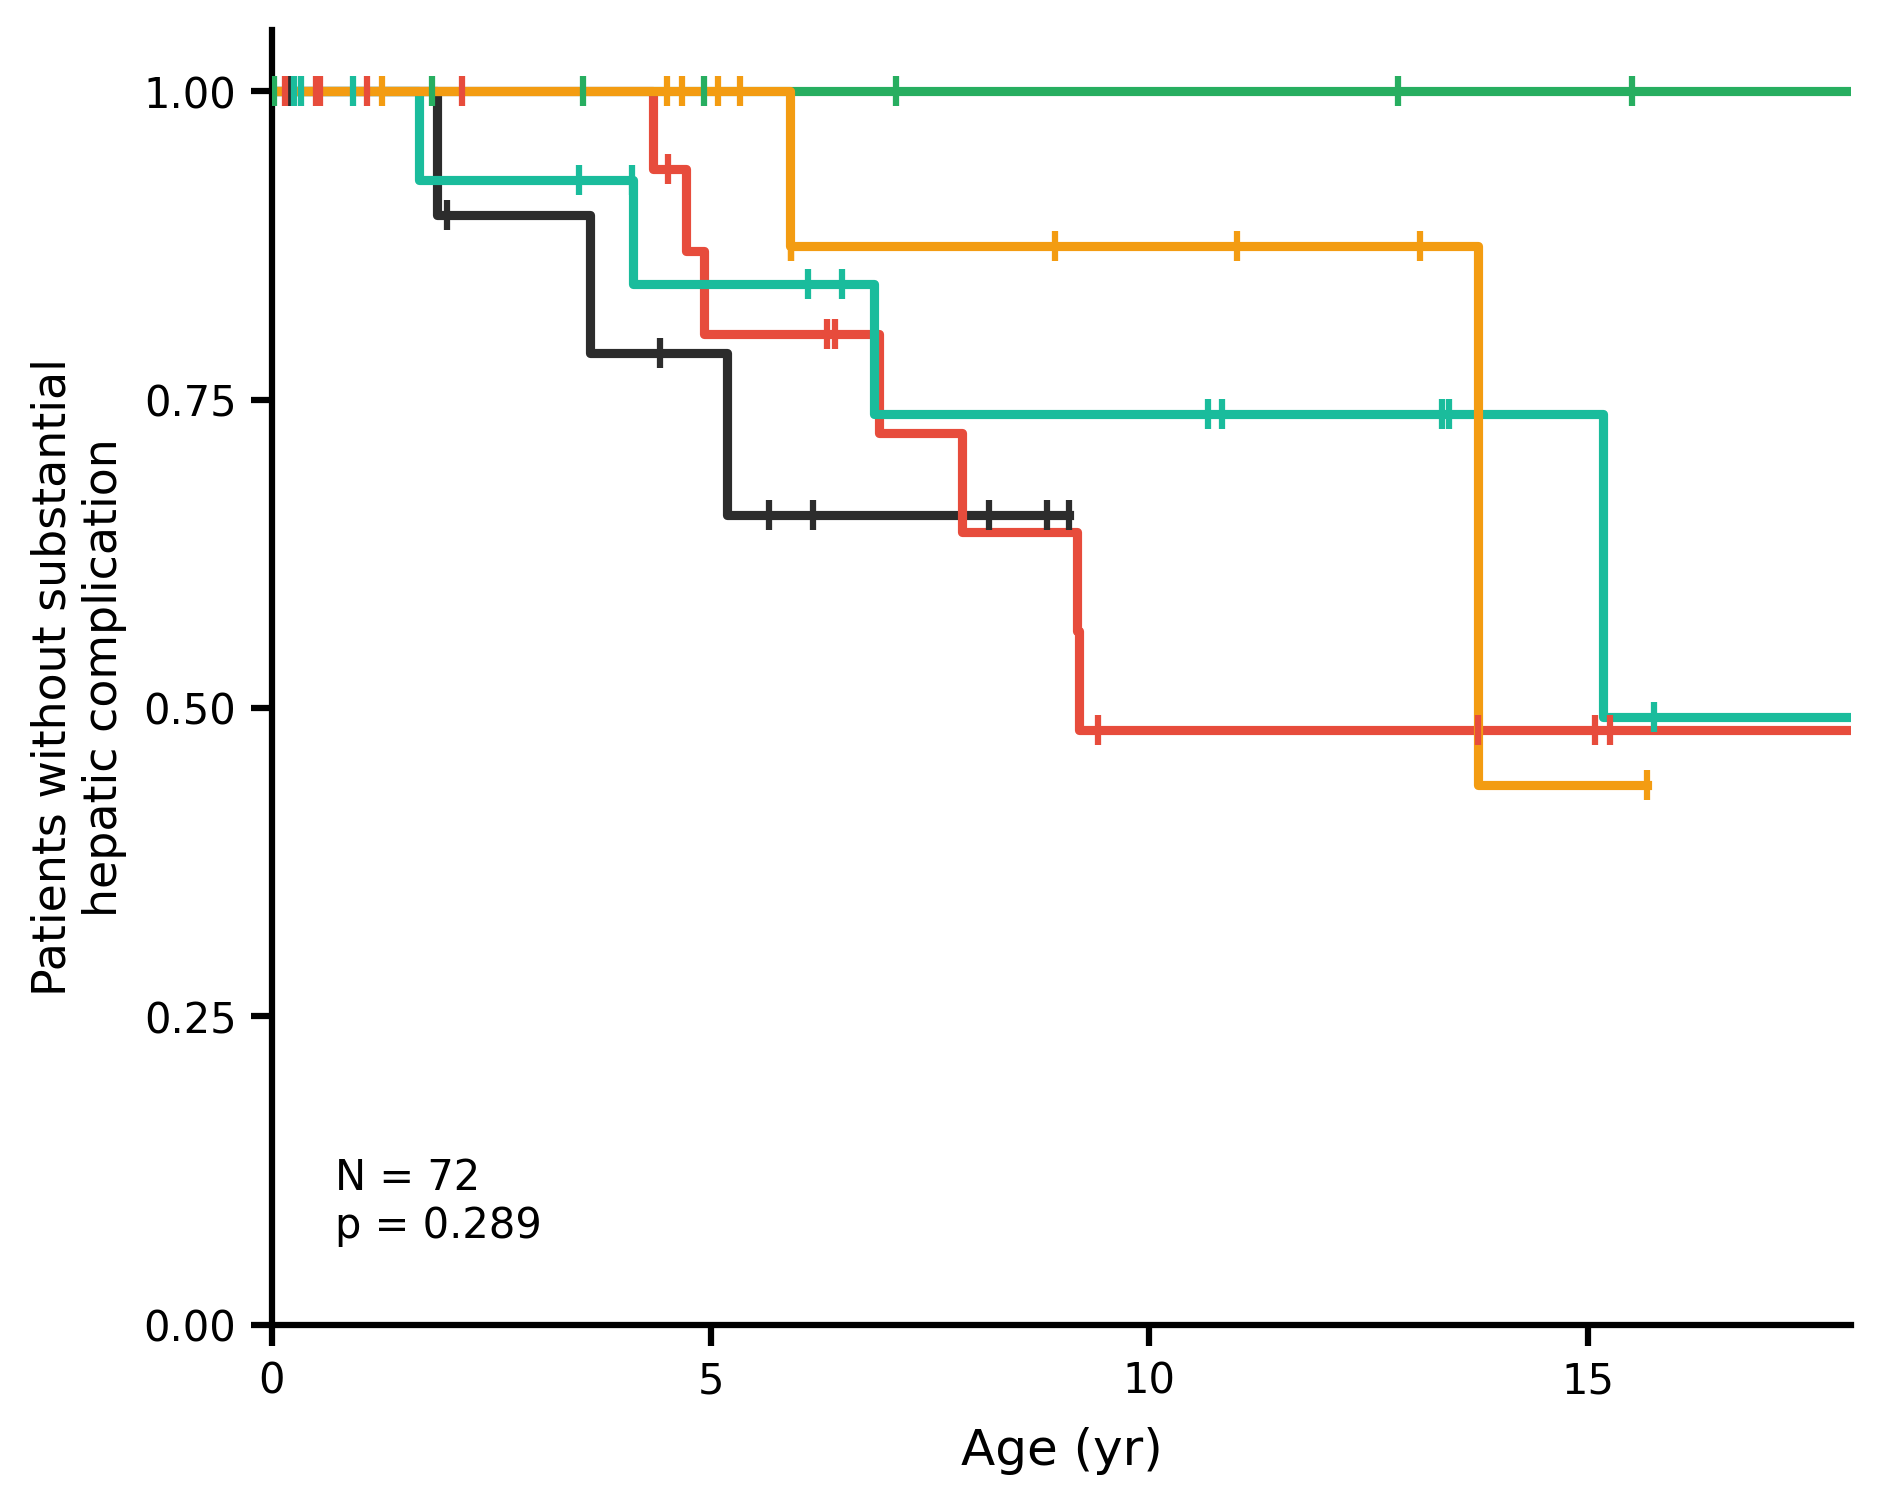

Saved: km_hepatic.png


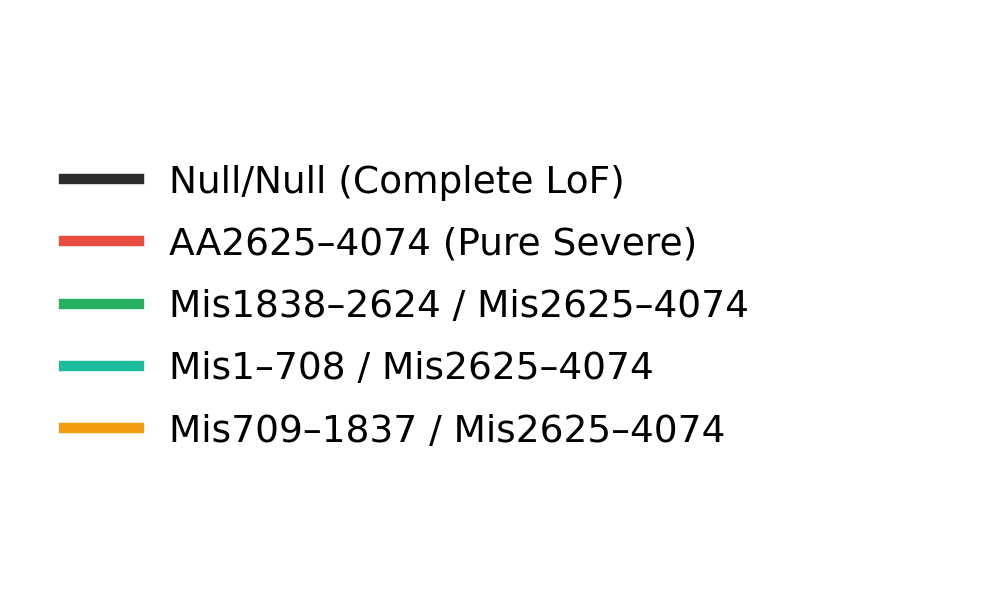

Saved: km_hepatic_legend.png

───────────────────────────────────────────────────────
STATISTICS — KM_HEPATIC
Overall log-rank: N=72, p = 0.289

Pairwise log-rank:
  Null/Null vs AA2625–4074: p = 0.665
  AA2625–4074 vs Mis1838/Mis2625: p = 0.083
  AA2625–4074 vs Mis1-708/Mis2625: p = 0.699
  AA2625–4074 vs Mis709/Mis2625: p = 0.348
  Null/Null vs Mis1838/Mis2625: p = 0.169

At-risk counts:
  Region                                  0     5    10    15
  Null/Null                              13     6     0     0
  AA2625–4074                            21    12     5     4
  Mis1838–2624 / Mis2625–4074             8     4     3     2
  Mis1–708 / Mis2625–4074                17    10     7     3
  Mis709–1837 / Mis2625–4074             13    10     4     1
───────────────────────────────────────────────────────



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ── 10. KM plots ──────────────────────────────────────────────────────────

plt.rcParams.update({
    'font.family':       'DejaVu Sans',
    'font.size':         11,
    'axes.linewidth':    1.5,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'xtick.major.width': 1.5,
    'ytick.major.width': 1.5,
    'xtick.major.size':  5,
    'ytick.major.size':  5,
    'figure.dpi':        300,
    'figure.facecolor':  'none',
    'axes.facecolor':    'none',
})

ladder = ['Null_Null', 'AA2625_4074',
          'Mis1838_Mis2625', 'Mis1_708_Mis2625', 'Mis709_Mis2625']

labels = ['Null/Null (Complete LoF)',
          'AA2625–4074 (Pure Severe)',
          'Mis1838–2624 / Mis2625–4074',
          'Mis1–708 / Mis2625–4074',
          'Mis709–1837 / Mis2625–4074']

colors = ['#2c2c2c', '#e74c3c', '#27ae60', '#1abc9c', '#f39c12']

km_pairs = [
    ('Null_Null',       'AA2625_4074',      'Null/Null vs AA2625–4074'),
    ('AA2625_4074',     'Mis1838_Mis2625',  'AA2625–4074 vs Mis1838/Mis2625'),
    ('AA2625_4074',     'Mis1_708_Mis2625', 'AA2625–4074 vs Mis1-708/Mis2625'),
    ('AA2625_4074',     'Mis709_Mis2625',   'AA2625–4074 vs Mis709/Mis2625'),
    ('Null_Null',       'Mis1838_Mis2625',  'Null/Null vs Mis1838/Mis2625'),
]

endpoints = [
    ('had_krt',        'krt_age',
     'Patients without KRT',                               'km_krt'),
    ('had_portal_htn', 'portal_htn_age',
     'Patients without portal hypertension',               'km_portal_htn'),
    ('had_hepatic',    'hepatic_age',
     'Patients without substantial\nhepatic complication', 'km_hepatic'),
]

timepoints = [0, 5, 10, 15]

for (event_col, age_col, ylabel, fname_base) in endpoints:

    fig, ax = plt.subplots(figsize=(6.5, 5.2))
    fig.patch.set_alpha(0)
    ax.patch.set_alpha(0)
    fig.subplots_adjust(left=0.16, right=0.97, top=0.96, bottom=0.13)

    n_total = 0
    for region, label, color in zip(ladder, labels, colors):
        subset   = combined[combined['region'] == region].copy()
        n_total += len(subset)
        duration, event = prepare_survival(subset, event_col, age_col)
        kmf = KaplanMeierFitter()
        kmf.fit(duration, event_observed=event)
        kmf.plot_survival_function(
            ax=ax, ci_show=False, color=color,
            linewidth=2.2, label=label,
        )
        censored_times = duration[event == 0]
        if len(censored_times) > 0:
            censored_probs = kmf.survival_function_at_times(censored_times).values
            ax.scatter(censored_times, censored_probs,
                       marker='|', color=color, s=50,
                       linewidth=1.5, zorder=5)

    # Overall log-rank
    durations_all, events_all, groups_all = [], [], []
    for region in ladder:
        subset = combined[combined['region'] == region].copy()
        d, e   = prepare_survival(subset, event_col, age_col)
        durations_all.extend(d)
        events_all.extend(e)
        groups_all.extend([region] * len(d))
    result = multivariate_logrank_test(durations_all, groups_all, events_all)

    ax.text(0.04, 0.06, f'N = {n_total}\n{fmt_p(result.p_value)}',
            transform=ax.transAxes, fontsize=10, va='bottom')

    leg = ax.get_legend()
    if leg: leg.remove()

    ax.set_xlim(0, 18)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('Age (yr)', fontsize=12, labelpad=6)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_xticks([0, 5, 10, 15])
    ax.set_yticks([0.00, 0.25, 0.50, 0.75, 1.00])
    ax.yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, _: f'{x:.2f}'))
    ax.tick_params(axis='both', labelsize=10)

    plt.savefig(f'{fname_base}.png', dpi=300,
                bbox_inches='tight', transparent=True)
    plt.show()
    print(f'Saved: {fname_base}.png')

    # ── Legend PNG ────────────────────────────────────────────────────────
    fig_leg, ax_leg = plt.subplots(figsize=(4.0, 2.4))
    fig_leg.patch.set_alpha(0)
    ax_leg.patch.set_alpha(0)
    ax_leg.axis('off')
    handles = [plt.Line2D([0], [0], color=c, linewidth=2.5) for c in colors]
    ax_leg.legend(handles, labels, loc='center left',
                  fontsize=9, frameon=False,
                  handlelength=2.0, labelspacing=0.7)
    plt.savefig(f'{fname_base}_legend.png', dpi=300,
                bbox_inches='tight', transparent=True)
    plt.show()
    print(f'Saved: {fname_base}_legend.png')

    # ── Print stats ───────────────────────────────────────────────────────
    print(f'\n{"─"*55}')
    print(f'STATISTICS — {fname_base.upper()}')
    print(f'Overall log-rank: N={n_total}, {fmt_p(result.p_value)}')
    print('\nPairwise log-rank:')
    for r1, r2, plabel in km_pairs:
        s1 = combined[combined['region'] == r1]
        s2 = combined[combined['region'] == r2]
        d1, e1 = prepare_survival(s1, event_col, age_col)
        d2, e2 = prepare_survival(s2, event_col, age_col)
        lr = logrank_test(d1, d2, e1, e2)
        print(f'  {plabel}: {fmt_p(lr.p_value)}')

    print('\nAt-risk counts:')
    header = f"  {'Region':<35}" + ''.join(f'{t:>6}' for t in timepoints)
    print(header)
    for region, label in zip(ladder, labels):
        subset    = combined[combined['region'] == region].copy()
        n_total_r = len(subset)
        duration, event = prepare_survival(subset, event_col, age_col)
        counts = [n_total_r if t == 0 else int(np.sum(duration >= t))
                  for t in timepoints]
        short = label.split('(')[0].strip()
        print(f"  {short:<35}" + ''.join(f'{c:>6}' for c in counts))
    print(f'{"─"*55}\n')

# ── 11. Download all output files ─────────────────────────────────────────
for fname in ['km_krt.png',        'km_krt_legend.png',
              'km_portal_htn.png', 'km_portal_htn_legend.png',
              'km_hepatic.png',    'km_hepatic_legend.png']:
    files.download(fname)

In [ ]:
print("── Hepatic event rates ──")
for region, label in zip(ladder, labels):
    subset = combined[combined['region'] == region]
    rate   = subset['had_hepatic'].mean()
    n      = len(subset)
    events = subset['had_hepatic'].sum()
    print(f"  {label:<35} {events}/{n} ({rate*100:.0f}%)")

print("\n── Portal HTN event rates ──")
for region, label in zip(ladder, labels):
    subset = combined[combined['region'] == region]
    rate   = subset['had_portal_htn'].mean()
    n      = len(subset)
    events = subset['had_portal_htn'].sum()
    print(f"  {label:<35} {events}/{n} ({rate*100:.0f}%)")

print("\n── Fisher's Exact vs AA2625_4074 ──")
severe = combined[combined['region'] == 'AA2625_4074']
for region, label in zip(ladder[2:], labels[2:]):
    subset = combined[combined['region'] == region]
    for event, ename in [('had_hepatic','Hepatic'), ('had_portal_htn','Portal HTN')]:
        a = subset[event].values
        b = severe[event].values
        table = [[sum(a==1), sum(a==0)], [sum(b==1), sum(b==0)]]
        OR, p = stats.fisher_exact(table)
        print(f"  {label.split('/')[0].strip()} vs Severe | {ename:<12} OR={OR:.2f}  {fmt_p(p)}  {'*' if p<0.05 else 'ns'}")

── Hepatic event rates ──
  Null/Null (Complete LoF)            3/13 (23%)
  AA2625–4074 (Pure Severe)           8/21 (38%)
  Mis1838–2624 / Mis2625–4074         0/8 (0%)
  Mis1–708 / Mis2625–4074             5/17 (29%)
  Mis709–1837 / Mis2625–4074          2/13 (15%)

── Portal HTN event rates ──
  Null/Null (Complete LoF)            9/13 (69%)
  AA2625–4074 (Pure Severe)           16/21 (76%)
  Mis1838–2624 / Mis2625–4074         1/8 (12%)
  Mis1–708 / Mis2625–4074             11/17 (65%)
  Mis709–1837 / Mis2625–4074          7/13 (54%)

── Fisher's Exact vs AA2625_4074 ──
  Mis1838–2624 vs Severe | Hepatic      OR=0.00  p = 0.066  ns
  Mis1838–2624 vs Severe | Portal HTN   OR=0.04  p = 0.003  *
  Mis1–708 vs Severe | Hepatic      OR=0.68  p = 0.734  ns
  Mis1–708 vs Severe | Portal HTN   OR=0.57  p = 0.491  ns
  Mis709–1837 vs Severe | Hepatic      OR=0.30  p = 0.251  ns
  Mis709–1837 vs Severe | Portal HTN   OR=0.36  p = 0.262  ns
